#Building a Deep Learning Computer Vision **CNN**

Get The Data

In [1]:
import urllib.request

url = "https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_all_data.zip"

urllib.request.urlretrieve(url, "10_food_classes_all_data.zip")

print("Téléchargement terminé !")

Téléchargement terminé !


## Unzip The zipped file

In [2]:
import zipfile
import os

# Si le fichier zip n'est pas présent, on le télécharge à nouveau
if not os.path.exists("10_food_classes_all_data.zip"):
    print("Téléchargement du fichier zip...")
    !wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_all_data.zip

# Extraction vers le répertoire courant
with zipfile.ZipFile("10_food_classes_all_data.zip", "r") as zip_ref:
    zip_ref.extractall("./")
print("Extraction terminée avec succès !")

Extraction terminée avec succès !


# Nice - We have gotten the Data

Understanding The data

In [3]:
import os
for dirpath, dirnames, filenames in os.walk("10_food_classes_all_data"):
  print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}")

There are 2 directories and 0 images in '10_food_classes_all_data
There are 10 directories and 0 images in '10_food_classes_all_data\test
There are 0 directories and 250 images in '10_food_classes_all_data\test\chicken_curry
There are 0 directories and 250 images in '10_food_classes_all_data\test\chicken_wings
There are 0 directories and 250 images in '10_food_classes_all_data\test\fried_rice
There are 0 directories and 250 images in '10_food_classes_all_data\test\grilled_salmon
There are 0 directories and 250 images in '10_food_classes_all_data\test\hamburger
There are 0 directories and 250 images in '10_food_classes_all_data\test\ice_cream
There are 0 directories and 250 images in '10_food_classes_all_data\test\pizza
There are 0 directories and 250 images in '10_food_classes_all_data\test\ramen
There are 0 directories and 250 images in '10_food_classes_all_data\test\steak
There are 0 directories and 250 images in '10_food_classes_all_data\test\sushi
There are 10 directories and 0 ima

Good, now we have known how many images we have...

In [4]:
train_dir = "10_food_classes_all_data/train/"
test_dir = "10_food_classes_all_data/test/"

In [5]:

import pathlib
import numpy as np

data_dir = pathlib.Path(train_dir)
class_names = np.array(sorted([item.name for item in data_dir.glob('*')]))
print(class_names)

['chicken_curry' 'chicken_wings' 'fried_rice' 'grilled_salmon' 'hamburger'
 'ice_cream' 'pizza' 'ramen' 'steak' 'sushi']


## Visualizing the food images

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


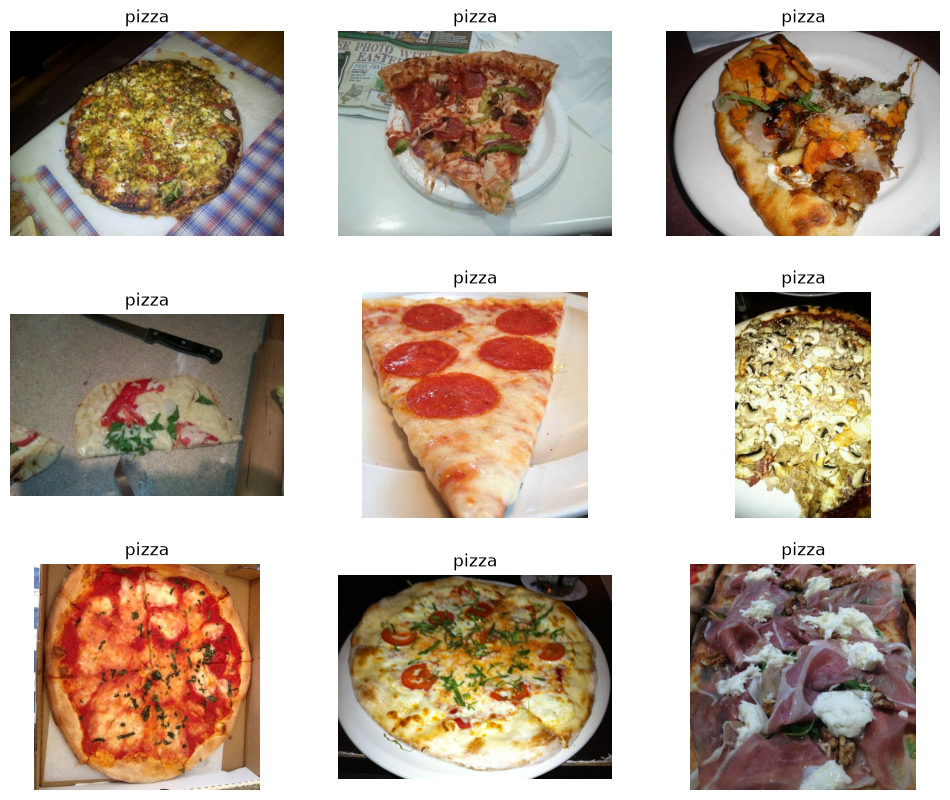

In [6]:
%pip install matplotlib
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

plt.figure(figsize=(12, 10))

def visualize_food_imag(category):
  for i in range(9):
    plt.subplot(3, 3, i+1)
    if category == "all":
      random_class_name = random.choice(class_names)
    else:
      random_class_name = category
    all_imgs = os.listdir(f"{train_dir}{random_class_name}")
    sample_img = random.sample(all_imgs, 1)[0]
    img = mpimg.imread(f"{train_dir}{random_class_name}/{sample_img}")
    plt.imshow(img)
    plt.axis("off")
    plt.title(random_class_name)
visualize_food_imag("pizza")

In [7]:
all_imgs = os.listdir(f"{train_dir}ice_cream")
sample_img = train_dir + "ice_cream/" + random.sample(all_imgs, 1)[0]
img_array = mpimg.imread(sample_img)
img_array


array([[[ 17,  13,  14],
        [ 19,  15,  16],
        [ 20,  16,  17],
        ...,
        [ 65,  38,  27],
        [ 71,  44,  33],
        [ 81,  54,  43]],

       [[ 17,  13,  14],
        [ 18,  14,  15],
        [ 20,  16,  17],
        ...,
        [ 68,  41,  30],
        [ 72,  45,  34],
        [ 77,  50,  39]],

       [[ 17,  11,  13],
        [ 18,  12,  14],
        [ 20,  14,  16],
        ...,
        [ 70,  47,  33],
        [ 69,  46,  32],
        [ 70,  47,  33]],

       ...,

       [[172, 165, 136],
        [174, 167, 138],
        [178, 169, 140],
        ...,
        [205, 189, 166],
        [206, 190, 167],
        [210, 194, 171]],

       [[171, 164, 135],
        [171, 164, 135],
        [174, 165, 136],
        ...,
        [207, 191, 168],
        [207, 191, 166],
        [206, 190, 165]],

       [[181, 174, 145],
        [177, 170, 141],
        [176, 167, 138],
        ...,
        [209, 193, 170],
        [208, 192, 167],
        [200, 184, 159]]

# Data preprocessing

Neural Network perform better when data is in a certain way.
1. we have to normalize the data . by diving/255:
2. We have to convert the array from the datatype 'uint8' into 'float32'.
3. We have to resize tho images into 224*224
4. We have to put our data into batches

In [8]:
%pip install tensorflow
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1/255. , # Data Normalization
                                  rotation_range = 0.2, # Data Augmentation
                                  width_shift_range=0.2, # Data Augmentation
                                  height_shift_range=0.2, # Data Augmentation
                                  zoom_range=0.2, # Data Augmentation
                                  horizontal_flip=True) # Data Augmentation
test_datgen = ImageDataGenerator(rescale=1/255.)

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
# Définition des chemins d'accès (au cas où la cellule précédente n'a pas été exécutée)
train_dir = "10_food_classes_all_data/train/"
test_dir = "10_food_classes_all_data/test/"

train_data = train_datagen.flow_from_directory(train_dir,
                                              target_size=(224, 224),
                                               batch_size = 32,
                                               class_mode = "categorical")
test_data = test_datgen.flow_from_directory(test_dir,
                                            target_size=(224, 224),
                                            batch_size = 32,
                                            class_mode = "categorical")

Found 7500 images belonging to 10 classes.
Found 2500 images belonging to 10 classes.


# Creating the model (Computer Vision (Convolutional Neural Networks) )

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Flatten, Dense, Activation

computer_vision_model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    Conv2D(filters=10, kernel_size=(3,3)),
    Activation(activation = "relu"), # Rectified Linear Unit
    Conv2D(filters=10, kernel_size=(3,3)),
    Activation(activation = "relu"),
    MaxPool2D(), # To Reduce Overfitting
    Conv2D(10, 3, activation = "relu"),
    Conv2D(10, 3, activation = "relu"),
    MaxPool2D(),
    Flatten(), # Converts the 2-Dimensional array into a vector (1-Dimention)
    Dense(10, activation = "softmax") # Softmax activation function coverts ten dense's output int probabilities (0, 1)
  ])


In [11]:
computer_vision_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 222, 222, 10)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 220, 220, 10)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 10)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 106, 106, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 53, 53, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28090)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │       280,910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 283,920 (1.08 MB)

 Trainable params: 283,920 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
computer_vision_model.compile(loss="categorical_crossentropy",
                              optimizer=tf.keras.optimizers.Adam(),
                              metrics=["accuracy"])

# Fitting the model

In [14]:
history = computer_vision_model.fit(train_data,
                                    epochs=5,
                                    validation_data=test_data,
                                    validation_batch_size=len(test_data))

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 100s 424ms/step - accuracy: 0.2768 - loss: 2.0443 - val_accuracy: 0.3820 - val_loss: 1.7985
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 97s 415ms/step - accuracy: 0.3100 - loss: 1.9602 - val_accuracy: 0.3836 - val_loss: 1.8144
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 98s 419ms/step - accuracy: 0.3325 - loss: 1.9236 - val_accuracy: 0.3616 - val_loss: 1.8525
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 111s 473ms/step - accuracy: 0.3497 - loss: 1.8780 - val_accuracy: 0.3792 - val_loss: 1.7702
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 110s 467ms/step - accuracy: 0.3531 - loss: 1.8512 - val_accuracy: 0.3724 - val_loss: 1.8291


We have trained the model

In [ ]:
import pandas as pd

In [ ]:
model_metrics = pd.DataFrame(history.history)
model_metrics

,accuracy,loss,val_accuracy,val_loss
0,0.118533,2.296373,0.1972,2.201999
1,0.197200,2.195525,0.2568,2.080833
2,0.258000,2.083375,0.3564,1.876585
3,0.305200,1.994002,0.3728,1.821751
4,0.323600,1.945716,0.3880,1.822799
5,0.338933,1.910682,0.3956,1.751759
6,0.350267,1.894732,0.4248,1.750875
7,0.357333,1.868837,0.4332,1.679256
8,0.373333,1.846117,0.4312,1.687295
9,0.378000,1.822123,0.4076,1.732768


<Axes: >

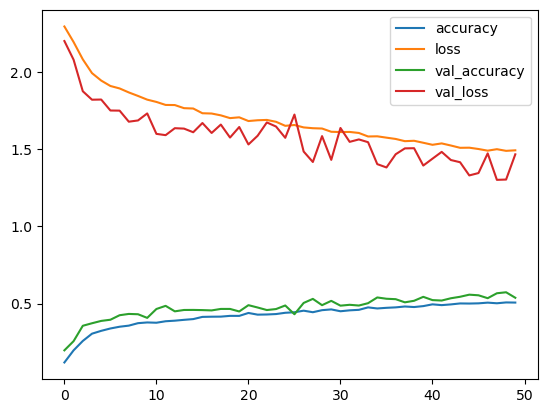

In [ ]:
model_metrics.plot()

In [ ]:
def load_and_prep_img(filename, img_shape=224):
  img = tf.io.read_file(filename)
  img = tf.image.decode_image(img)
  img = tf.image.resize(img, [img_shape, img_shape])
  img = img/255. #We have a normalize the img array
  return img

In [ ]:
def pred_and_plot(model, filename, class_names = class_names):
  img = load_and_prep_img(filename)

  pred = model.predict(tf.expand_dims(img, axis=0))


  if (len(pred[0])>1):
    pred_classes = class_names[tf.argmax(pred[0])]

  plt.imshow(img)
  plt.title(f"Prediction {pred_classes}")
  plt.axis(False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


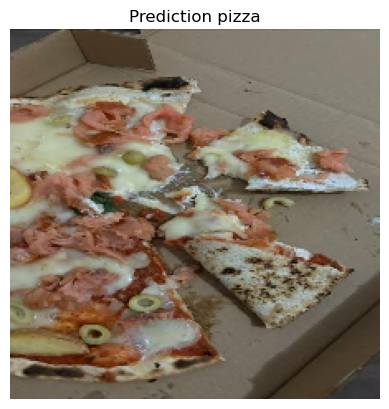

In [ ]:
pred_and_plot(computer_vision_model, "pizzaCarre.jpg")